# 🧬 BRCA TCGA Feature Audit, Missingness & Patient Graph Visualizations

This notebook provides empirical evidence for our feature selection policy:
1. **Audit of all columns and missing values** in `data_clinical_patient.txt` and `data_clinical_sample.txt`.
2. **Evidence supporting our exclusions** (100% missing fields like `WEIGHT` and `GRADE`, target leakage fields like survival outcomes, redundant fields).
3. **Molecular data preview** (`data_mutations.txt` and `data_cna.txt`).
4. **Visualizations of patient graphs with full patient and sample clinical attributes** integrated.

In [10]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(r'C:\Users\shaur\OneDrive\Desktop\Mycodes\primekg-patient-reasoning\brca_tcga_pan_can_atlas_2018')
OUTPUT_DIR = Path(r'C:\Users\shaur\OneDrive\Desktop\Mycodes\primekg-patient-reasoning\outputs')

def read_tsv(filename):
    with open(DATA_DIR / filename, 'r', encoding='utf-8') as f:
        lines = [l for l in f if not l.startswith('#')]
    from io import StringIO
    return pd.read_csv(StringIO(''.join(lines)), sep='\t', low_memory=False)

## 1. Clinical Patient Data: Picked vs Dropped Features
Let's inspect all 38 columns in `data_clinical_patient.txt`, calculate missingness counts, and see exactly which columns we kept vs dropped.

In [11]:
df_patient = read_tsv('data_clinical_patient.txt')

KEPT_PATIENT_COLS = ['PATIENT_ID', 'AGE', 'SEX', 'CANCER_TYPE_ACRONYM', 'SUBTYPE', 'AJCC_PATHOLOGIC_TUMOR_STAGE', 'PATH_M_STAGE']

# Compute missingness
missing_patient = df_patient.isna() | df_patient.isin(['', 'NA', 'N/A', 'Unknown', '[Unknown]'])
missing_counts = missing_patient.sum()
missing_pct = (missing_counts / len(df_patient) * 100).round(2)

patient_audit = pd.DataFrame({
    'Total Rows': len(df_patient),
    'Missing Count': missing_counts,
    'Missing %': missing_pct,
    'Status in Graph': ['KEPT (Patient Attribute)' if col in KEPT_PATIENT_COLS else 'DROPPED' for col in df_patient.columns],
    'Reason': [
        'Patient Identifier' if col == 'PATIENT_ID' else
        'Demographics' if col in ['AGE', 'SEX'] else
        'Cancer/Subtype Context' if col in ['CANCER_TYPE_ACRONYM', 'SUBTYPE'] else
        'Tumor Stage' if col in ['AJCC_PATHOLOGIC_TUMOR_STAGE', 'PATH_M_STAGE'] else
        'Target Leakage (Survival Outcome)' if any(col.startswith(p) for p in ['OS_', 'DSS_', 'DFS_', 'PFS_']) else
        '100% Missing in Cohort' if missing_counts[col] == len(df_patient) else
        'Redundant Stage (Covered by AJCC Stage)' if col in ['PATH_T_STAGE', 'PATH_N_STAGE'] else
        'Fairness/Demographic Risk' if col in ['RACE', 'ETHNICITY', 'GENETIC_ANCESTRY_LABEL'] else
        'Administrative / Registry Metadata' for col in df_patient.columns
    ]
})

print('=== TOTAL COLUMNS IN PATIENT TABLE:', len(df_patient.columns), '===')
patient_audit.sort_values(by=['Status in Graph', 'Missing %'], ascending=[True, False])

=== TOTAL COLUMNS IN PATIENT TABLE: 38 ===


,Total Rows,Missing Count,Missing %,Status in Graph,Reason
WEIGHT,1084,1084,100.00,DROPPED,100% Missing in Cohort
PRIMARY_LYMPH_NODE_PRESENTATION_ASSESSMENT,1084,364,33.58,DROPPED,Administrative / Registry Metadata
NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT,1084,199,18.36,DROPPED,Administrative / Registry Metadata
ETHNICITY,1084,169,15.59,DROPPED,Fairness/Demographic Risk
DFS_MONTHS,1084,143,13.19,DROPPED,Target Leakage (Survival Outcome)
DFS_STATUS,1084,142,13.10,DROPPED,Target Leakage (Survival Outcome)
AJCC_STAGING_EDITION,1084,140,12.92,DROPPED,Administrative / Registry Metadata
PERSON_NEOPLASM_CANCER_STATUS,1084,123,11.35,DROPPED,Administrative / Registry Metadata
DAYS_LAST_FOLLOWUP,1084,104,9.59,DROPPED,Administrative / Registry Metadata
RADIATION_THERAPY,1084,101,9.32,DROPPED,Administrative / Registry Metadata


## 2. Clinical Sample Data: Picked vs Dropped Features
Now let's inspect `data_clinical_sample.txt`.

In [12]:
df_sample = read_tsv('data_clinical_sample.txt')

KEPT_SAMPLE_COLS = ['SAMPLE_ID', 'PATIENT_ID', 'ONCOTREE_CODE', 'CANCER_TYPE', 'CANCER_TYPE_DETAILED', 'TUMOR_TYPE', 'SAMPLE_TYPE', 'ANEUPLOIDY_SCORE']

missing_sample = df_sample.isna() | df_sample.isin(['', 'NA', 'N/A', 'Unknown', '[Unknown]'])
sample_counts = missing_sample.sum()
sample_pct = (sample_counts / len(df_sample) * 100).round(2)

sample_audit = pd.DataFrame({
    'Total Rows': len(df_sample),
    'Missing Count': sample_counts,
    'Missing %': sample_pct,
    'Status in Graph': ['KEPT (Sample Attribute)' if col in KEPT_SAMPLE_COLS else 'DROPPED' for col in df_sample.columns],
    'Reason': [
        'Sample / Patient ID' if col in ['SAMPLE_ID', 'PATIENT_ID'] else
        'Oncology / Histology Classification' if col in ['ONCOTREE_CODE', 'CANCER_TYPE', 'CANCER_TYPE_DETAILED'] else
        'Tissue Specimen Type' if col in ['TUMOR_TYPE', 'SAMPLE_TYPE'] else
        'Chromosomal Instability Metric' if col == 'ANEUPLOIDY_SCORE' else
        '100% Missing in Cohort' if sample_counts[col] == len(df_sample) else
        'Algorithmic Score with High Missingness' if 'MSI' in col else
        'Derived Metric (We use exact raw count instead)' if 'TMB' in col else
        'Administrative / Lab Metadata' for col in df_sample.columns
    ]
})

print('=== TOTAL COLUMNS IN SAMPLE TABLE:', len(df_sample.columns), '===')
sample_audit.sort_values(by=['Status in Graph', 'Missing %'], ascending=[True, False])

=== TOTAL COLUMNS IN SAMPLE TABLE: 19 ===


,Total Rows,Missing Count,Missing %,Status in Graph,Reason
GRADE,1084,1084,100.00,DROPPED,100% Missing in Cohort
MSI_SCORE_MANTIS,1084,50,4.61,DROPPED,Algorithmic Score with High Missingness
TMB_NONSYNONYMOUS,1084,18,1.66,DROPPED,Derived Metric (We use exact raw count instead)
MSI_SENSOR_SCORE,1084,9,0.83,DROPPED,Algorithmic Score with High Missingness
TISSUE_PROSPECTIVE_COLLECTION_INDICATOR,1084,4,0.37,DROPPED,Administrative / Lab Metadata
TISSUE_RETROSPECTIVE_COLLECTION_INDICATOR,1084,4,0.37,DROPPED,Administrative / Lab Metadata
TBL_SCORE,1084,2,0.18,DROPPED,Administrative / Lab Metadata
TISSUE_SOURCE_SITE_CODE,1084,0,0.00,DROPPED,Administrative / Lab Metadata
TUMOR_TISSUE_SITE,1084,0,0.00,DROPPED,Administrative / Lab Metadata
SOMATIC_STATUS,1084,0,0.00,DROPPED,Administrative / Lab Metadata


## 3. Molecular Mutation & Copy Number Evidence
Inspecting `data_mutations.txt` and `data_cna.txt` columns.

In [13]:
# Inspect mutations columns
df_mut = read_tsv('data_mutations.txt')
print(f'Total Mutation Calls in Cohort: {len(df_mut):,}')
print(f'Total Columns in MAF file: {len(df_mut.columns)}')

KEPT_MUT_COLS = [
    'Hugo_Symbol', 'Entrez_Gene_Id', 'Tumor_Sample_Barcode', 'Variant_Classification',
    'Variant_Type', 'Consequence', 'HGVSp_Short', 'HGVSc', 'Chromosome', 'Start_Position',
    'End_Position', 'Reference_Allele', 'Tumor_Seq_Allele2', 'IMPACT', 'FILTER', 'NCALLERS'
]

print('\nColumns Kept as Edge Attributes on `has_mutation`:')
for col in KEPT_MUT_COLS:
    missing_n = (df_mut[col].isna() | df_mut[col].isin(['', 'NA', 'N/A', 'Unknown'])).sum()
    print(f'  • {col:<25} missing: {missing_n} ({missing_n/len(df_mut)*100:.2f}%)')

print('\nExamples of 95 Dropped Columns with high missingness:')
for col in ['COSMIC', 'HGVSp', 'Codons', 'RefSeq']:
    missing_n = (df_mut[col].isna() | df_mut[col].isin(['', 'NA', 'N/A', 'Unknown'])).sum()
    print(f'  • {col:<25} missing: {missing_n} ({missing_n/len(df_mut)*100:.2f}%)')

Total Mutation Calls in Cohort: 126,252
Total Columns in MAF file: 111

Columns Kept as Edge Attributes on `has_mutation`:
  • Hugo_Symbol               missing: 0 (0.00%)
  • Entrez_Gene_Id            missing: 15 (0.01%)
  • Tumor_Sample_Barcode      missing: 0 (0.00%)
  • Variant_Classification    missing: 0 (0.00%)
  • Variant_Type              missing: 0 (0.00%)
  • Consequence               missing: 0 (0.00%)
  • HGVSp_Short               missing: 9889 (7.83%)
  • HGVSc                     missing: 1220 (0.97%)
  • Chromosome                missing: 0 (0.00%)
  • Start_Position            missing: 0 (0.00%)
  • End_Position              missing: 0 (0.00%)
  • Reference_Allele          missing: 0 (0.00%)
  • Tumor_Seq_Allele2         missing: 0 (0.00%)
  • IMPACT                    missing: 0 (0.00%)
  • FILTER                    missing: 0 (0.00%)
  • NCALLERS                  missing: 0 (0.00%)

Examples of 95 Dropped Columns with high missingness:
  • COSMIC                    m

In [14]:
# Inspect CNA preview
with open(DATA_DIR / 'data_cna.txt', 'r', encoding='utf-8') as f:
    lines = [f.readline() for _ in range(6)]

header = lines[0].strip().split('\t')
print(f'data_cna.txt dimensions: 25,128 Genes x {len(header)-2} Samples')
print('First 6 columns in CNA matrix:', header[:6])
print('\nPreview of discrete calls:')
for l in lines[1:6]:
    vals = l.strip().split('\t')
    print(f'Gene: {vals[0]:<12} Entrez: {vals[1]:<8} Sample values: {vals[2:6]}')

data_cna.txt dimensions: 25,128 Genes x 1070 Samples
First 6 columns in CNA matrix: ['Hugo_Symbol', 'Entrez_Gene_Id', 'TCGA-3C-AAAU-01', 'TCGA-3C-AALI-01', 'TCGA-3C-AALJ-01', 'TCGA-3C-AALK-01']

Preview of discrete calls:
Gene: ACAP3        Entrez: 116983   Sample values: ['0', '-1', '-1', '0']
Gene: ACTRT2       Entrez: 140625   Sample values: ['0', '-1', '-1', '0']
Gene: AGRN         Entrez: 375790   Sample values: ['0', '-1', '-1', '0']
Gene: ANKRD65      Entrez: 441869   Sample values: ['0', '-1', '-1', '0']
Gene: ATAD3A       Entrez: 55210    Sample values: ['0', '-1', '-1', '0']


## 4. Patient Graph Visualizations with Clinical Attributes
Below are the generated patient graphs. Each visualization now clearly displays the **Patient Attributes** (Age, Sex, Subtype, Tumor Stage, Metastasis Code) and **Sample Attributes** (Oncotree, Specimen Type, Aneuploidy Score, Mutation Rows) alongside the molecular network.

=== TCGA-AR-A0TS: Basal Subtype, Stage IIB - High CNA & Mutations ===


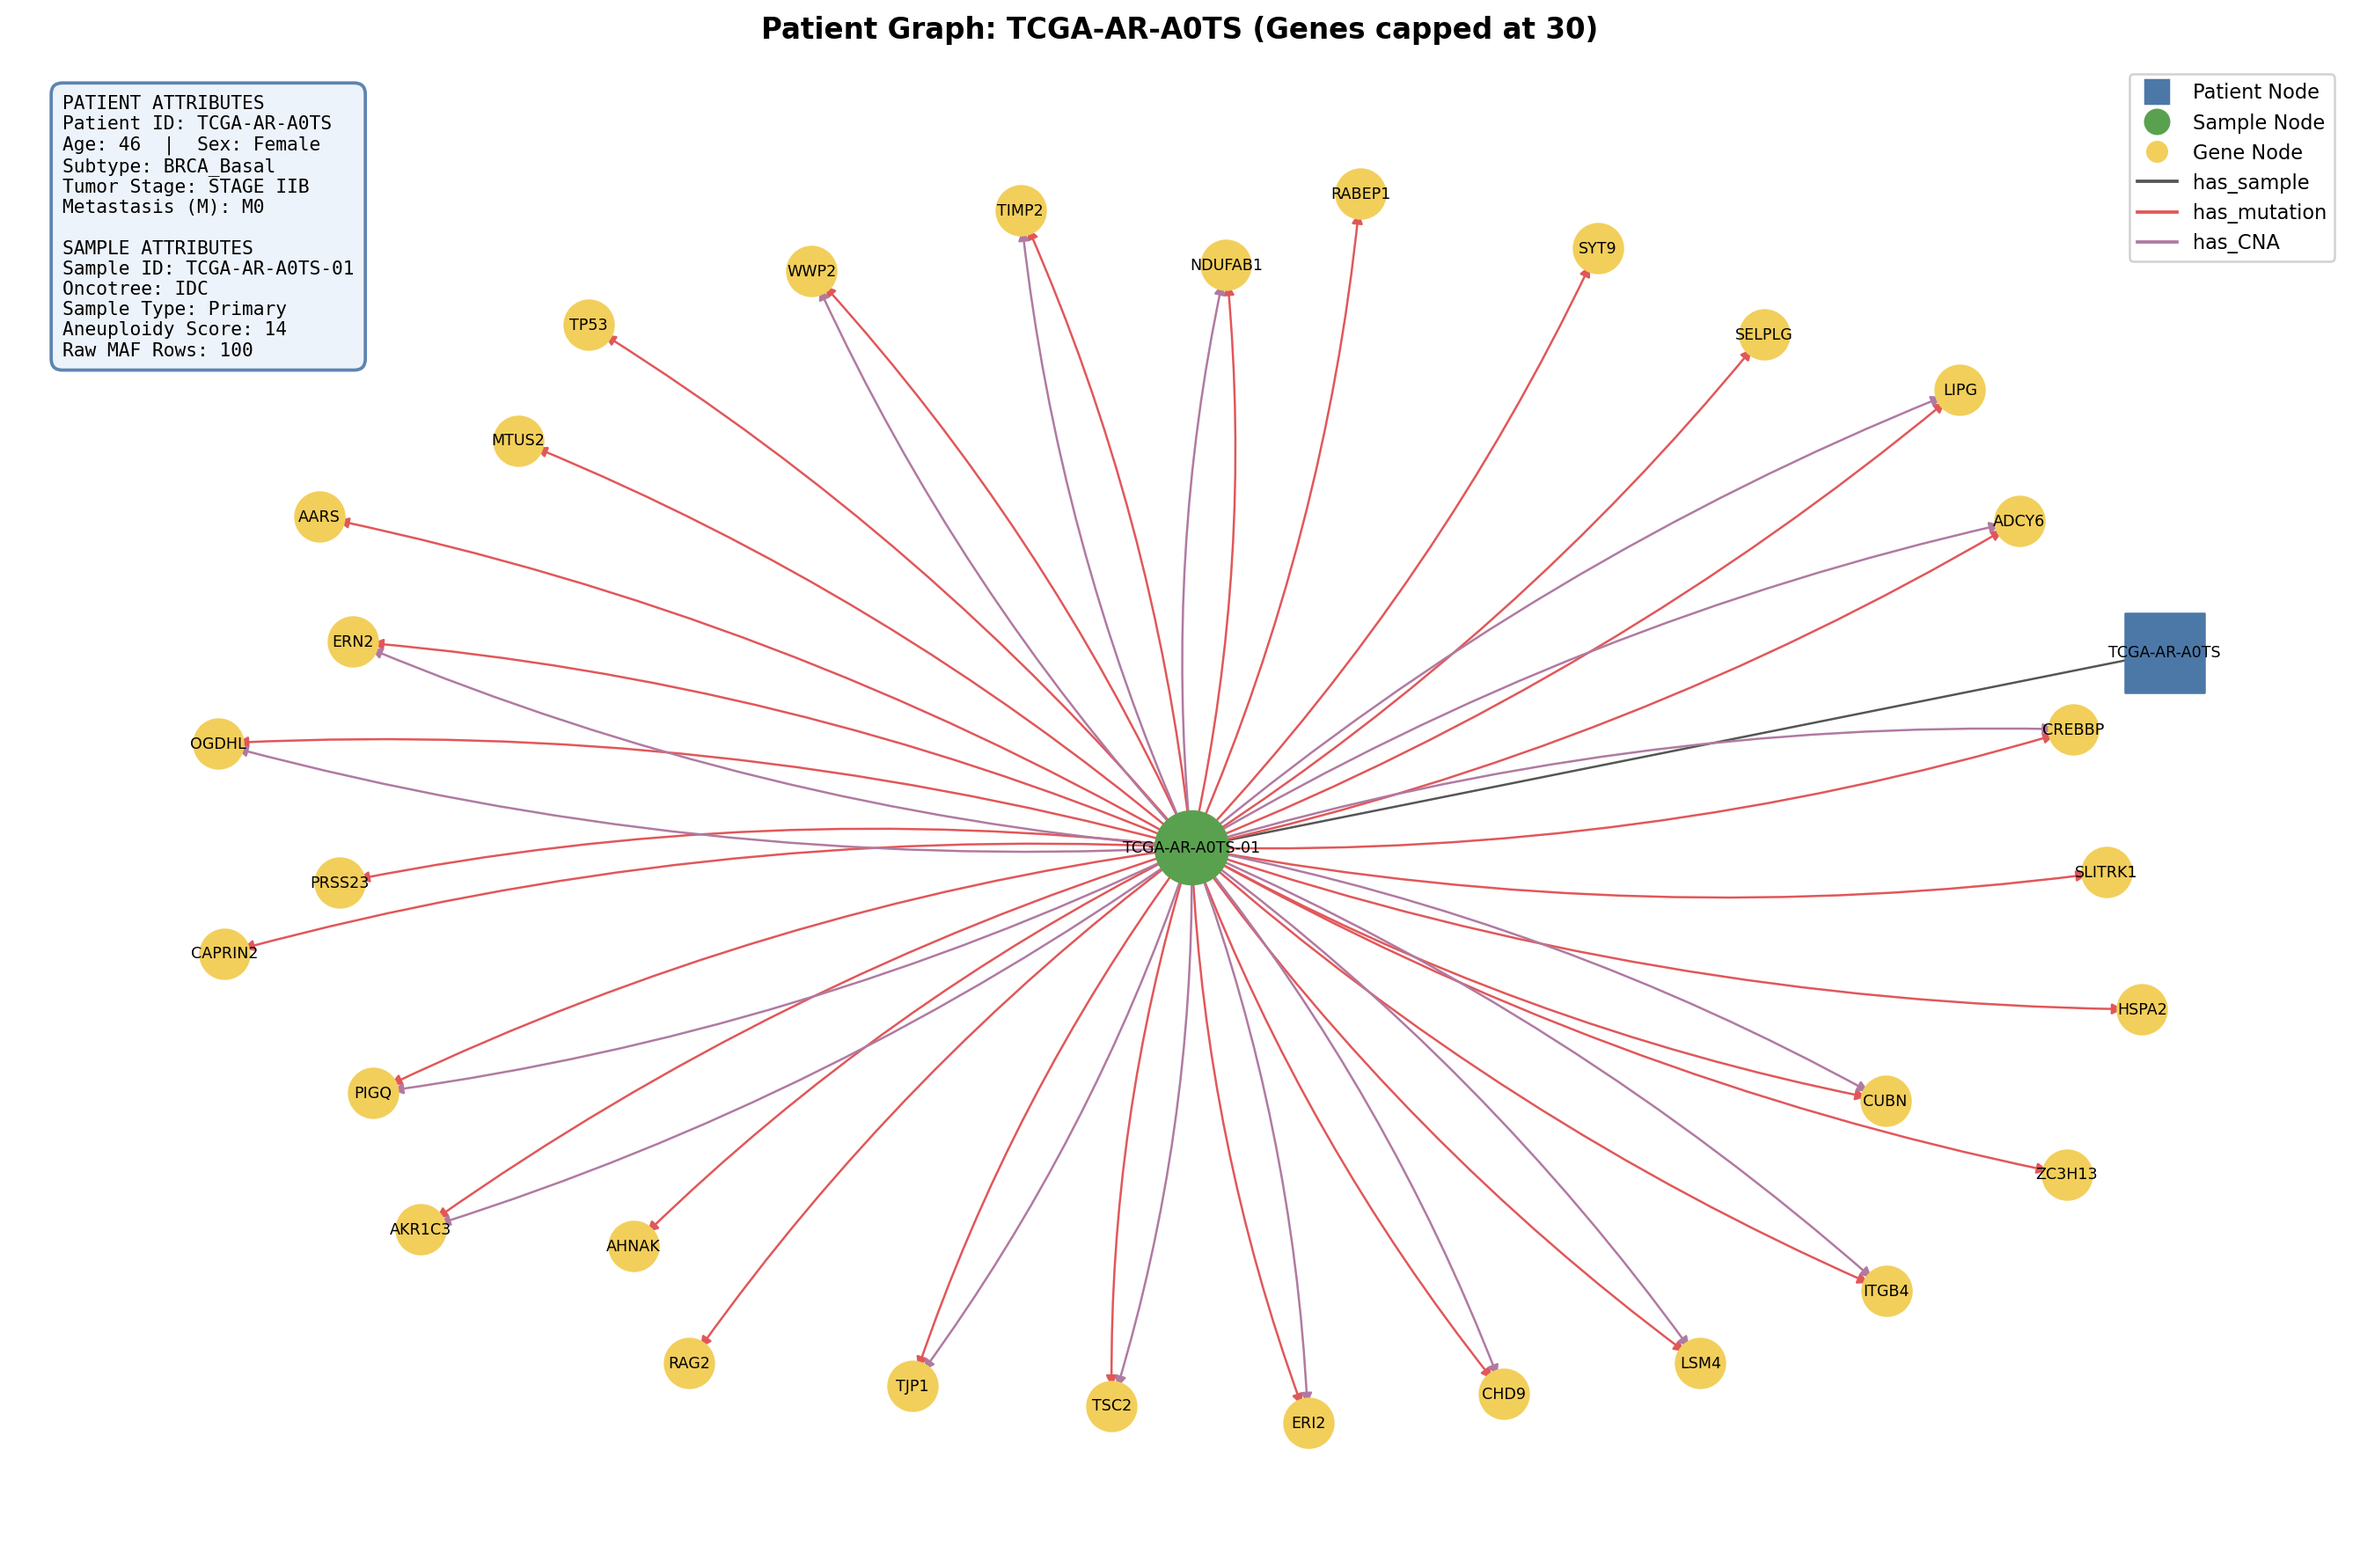

=== TCGA-BH-A0GZ: Luminal A Subtype, Stage IIA - Moderate Mutations ===


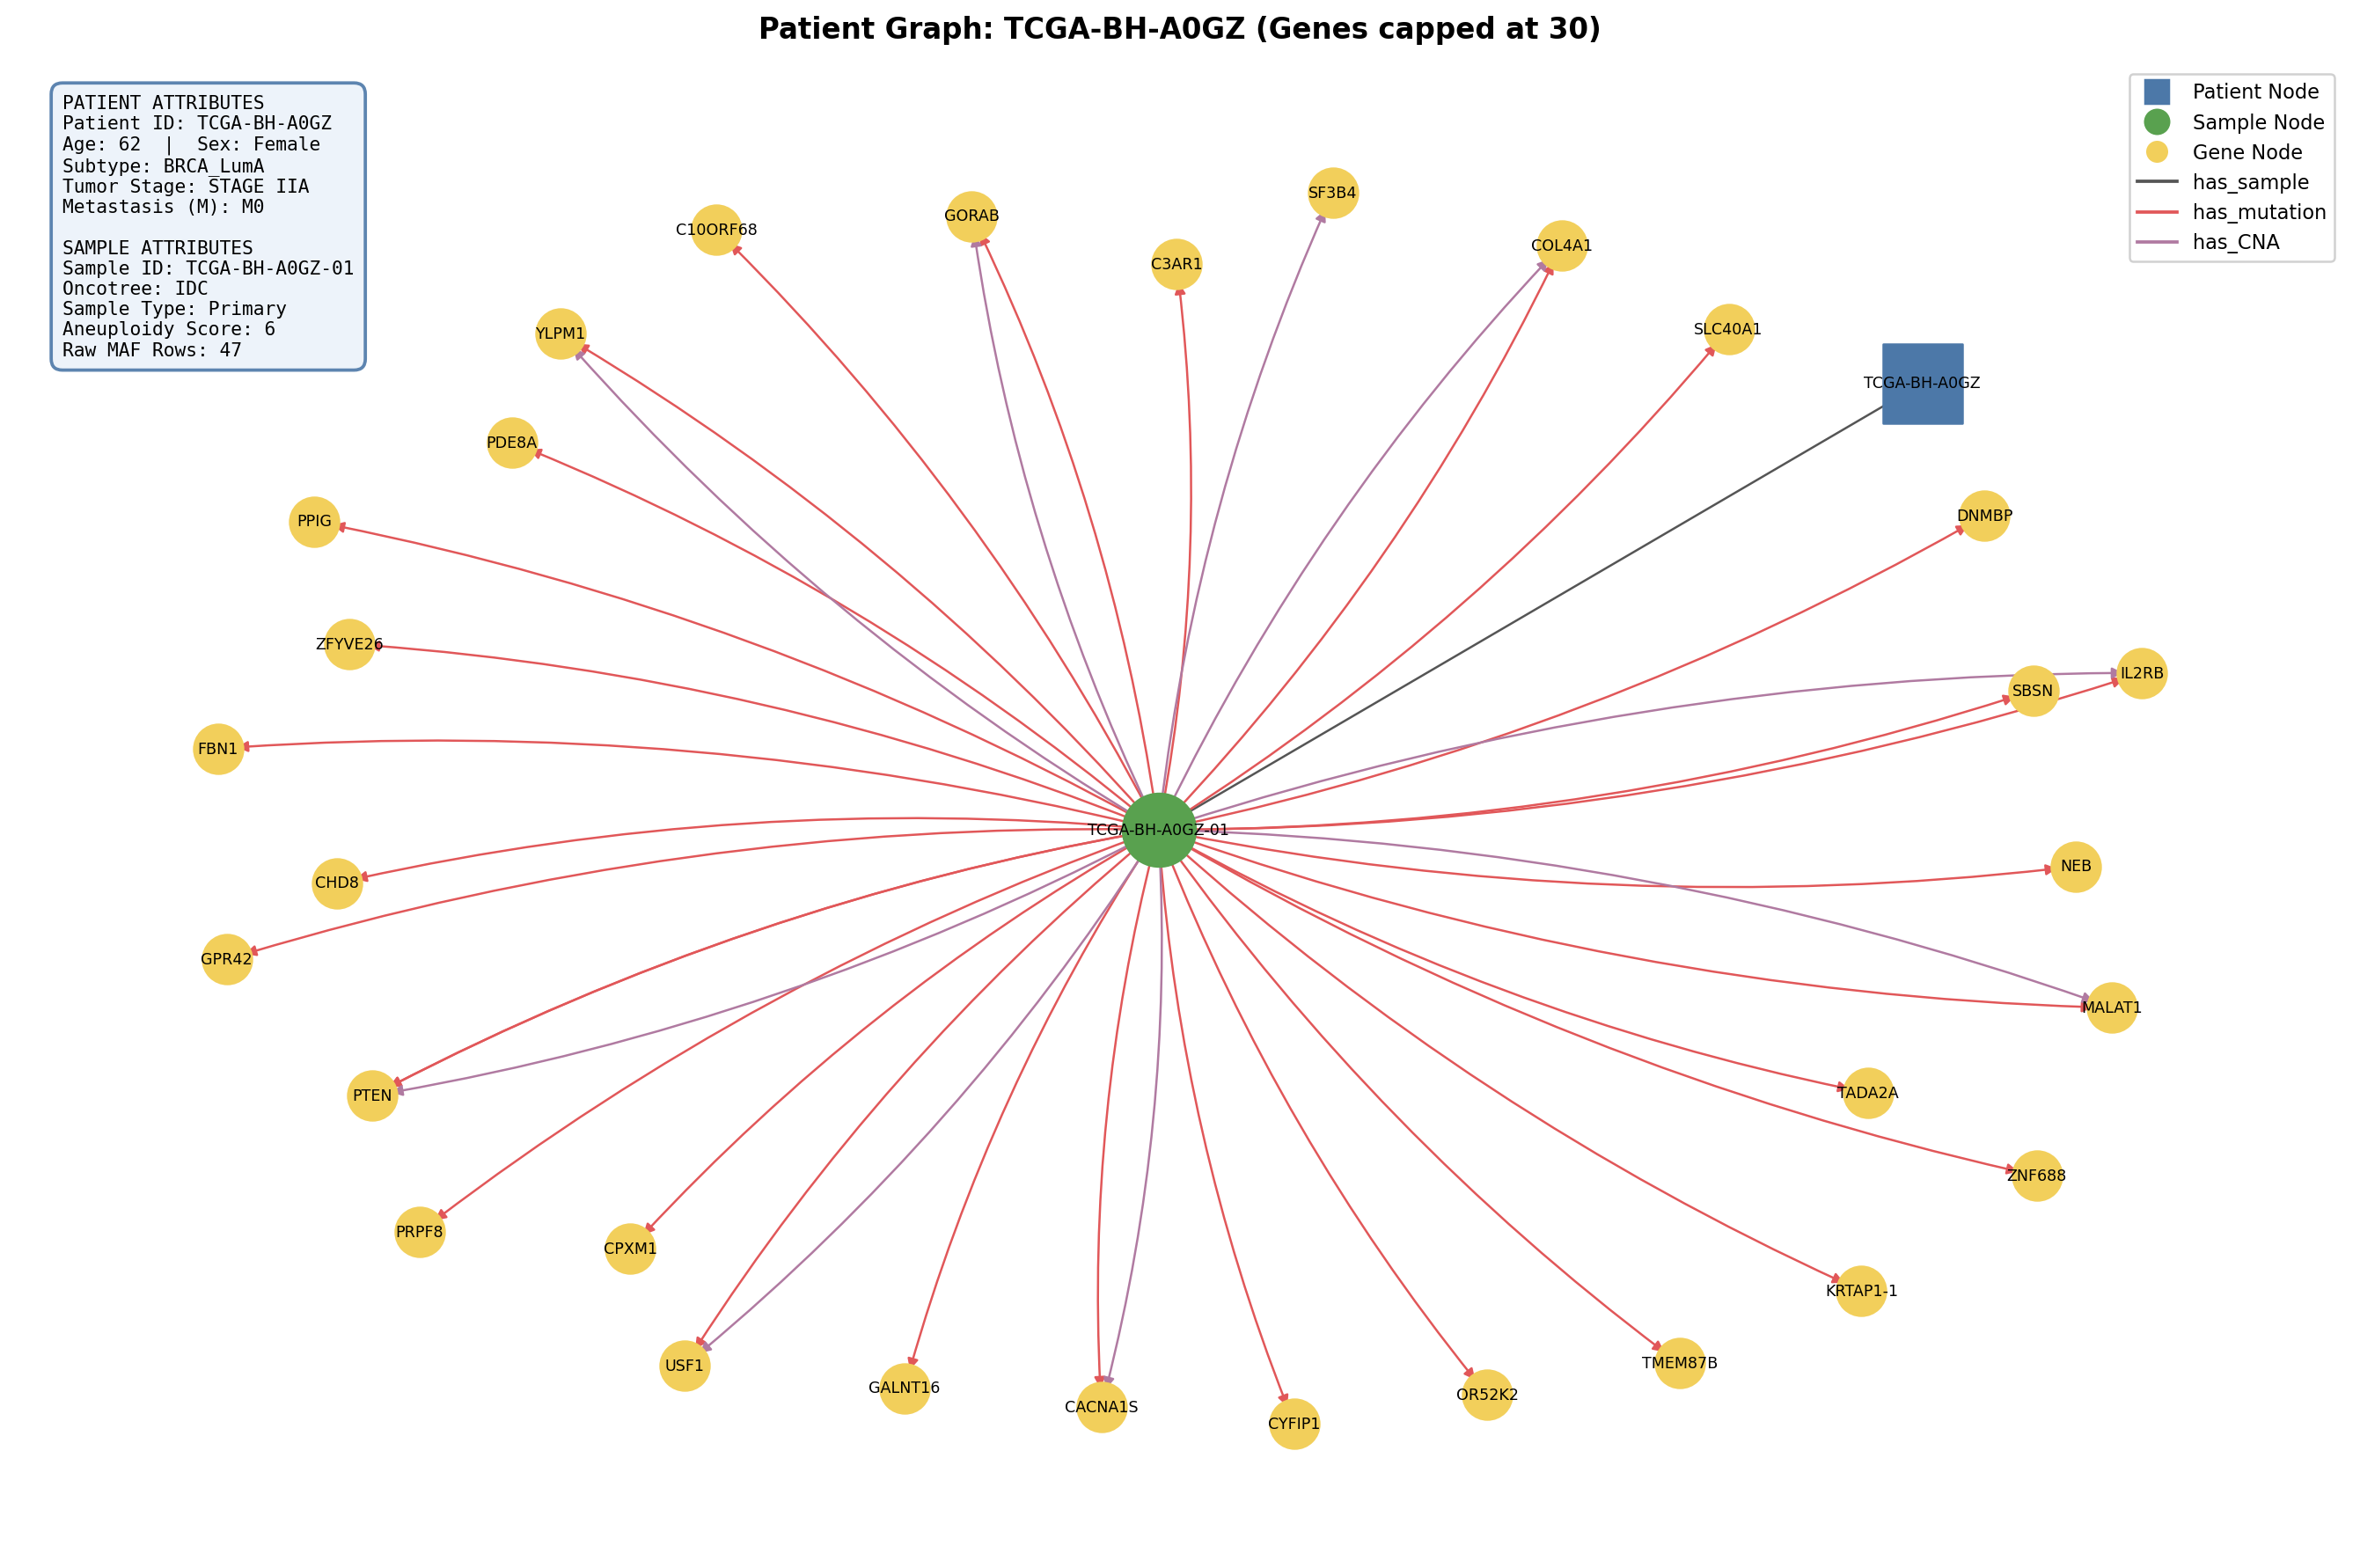

=== TCGA-HN-A2NL: Basal Subtype, Stage IIA - Extreme CNA Burden (24k+ genes) ===


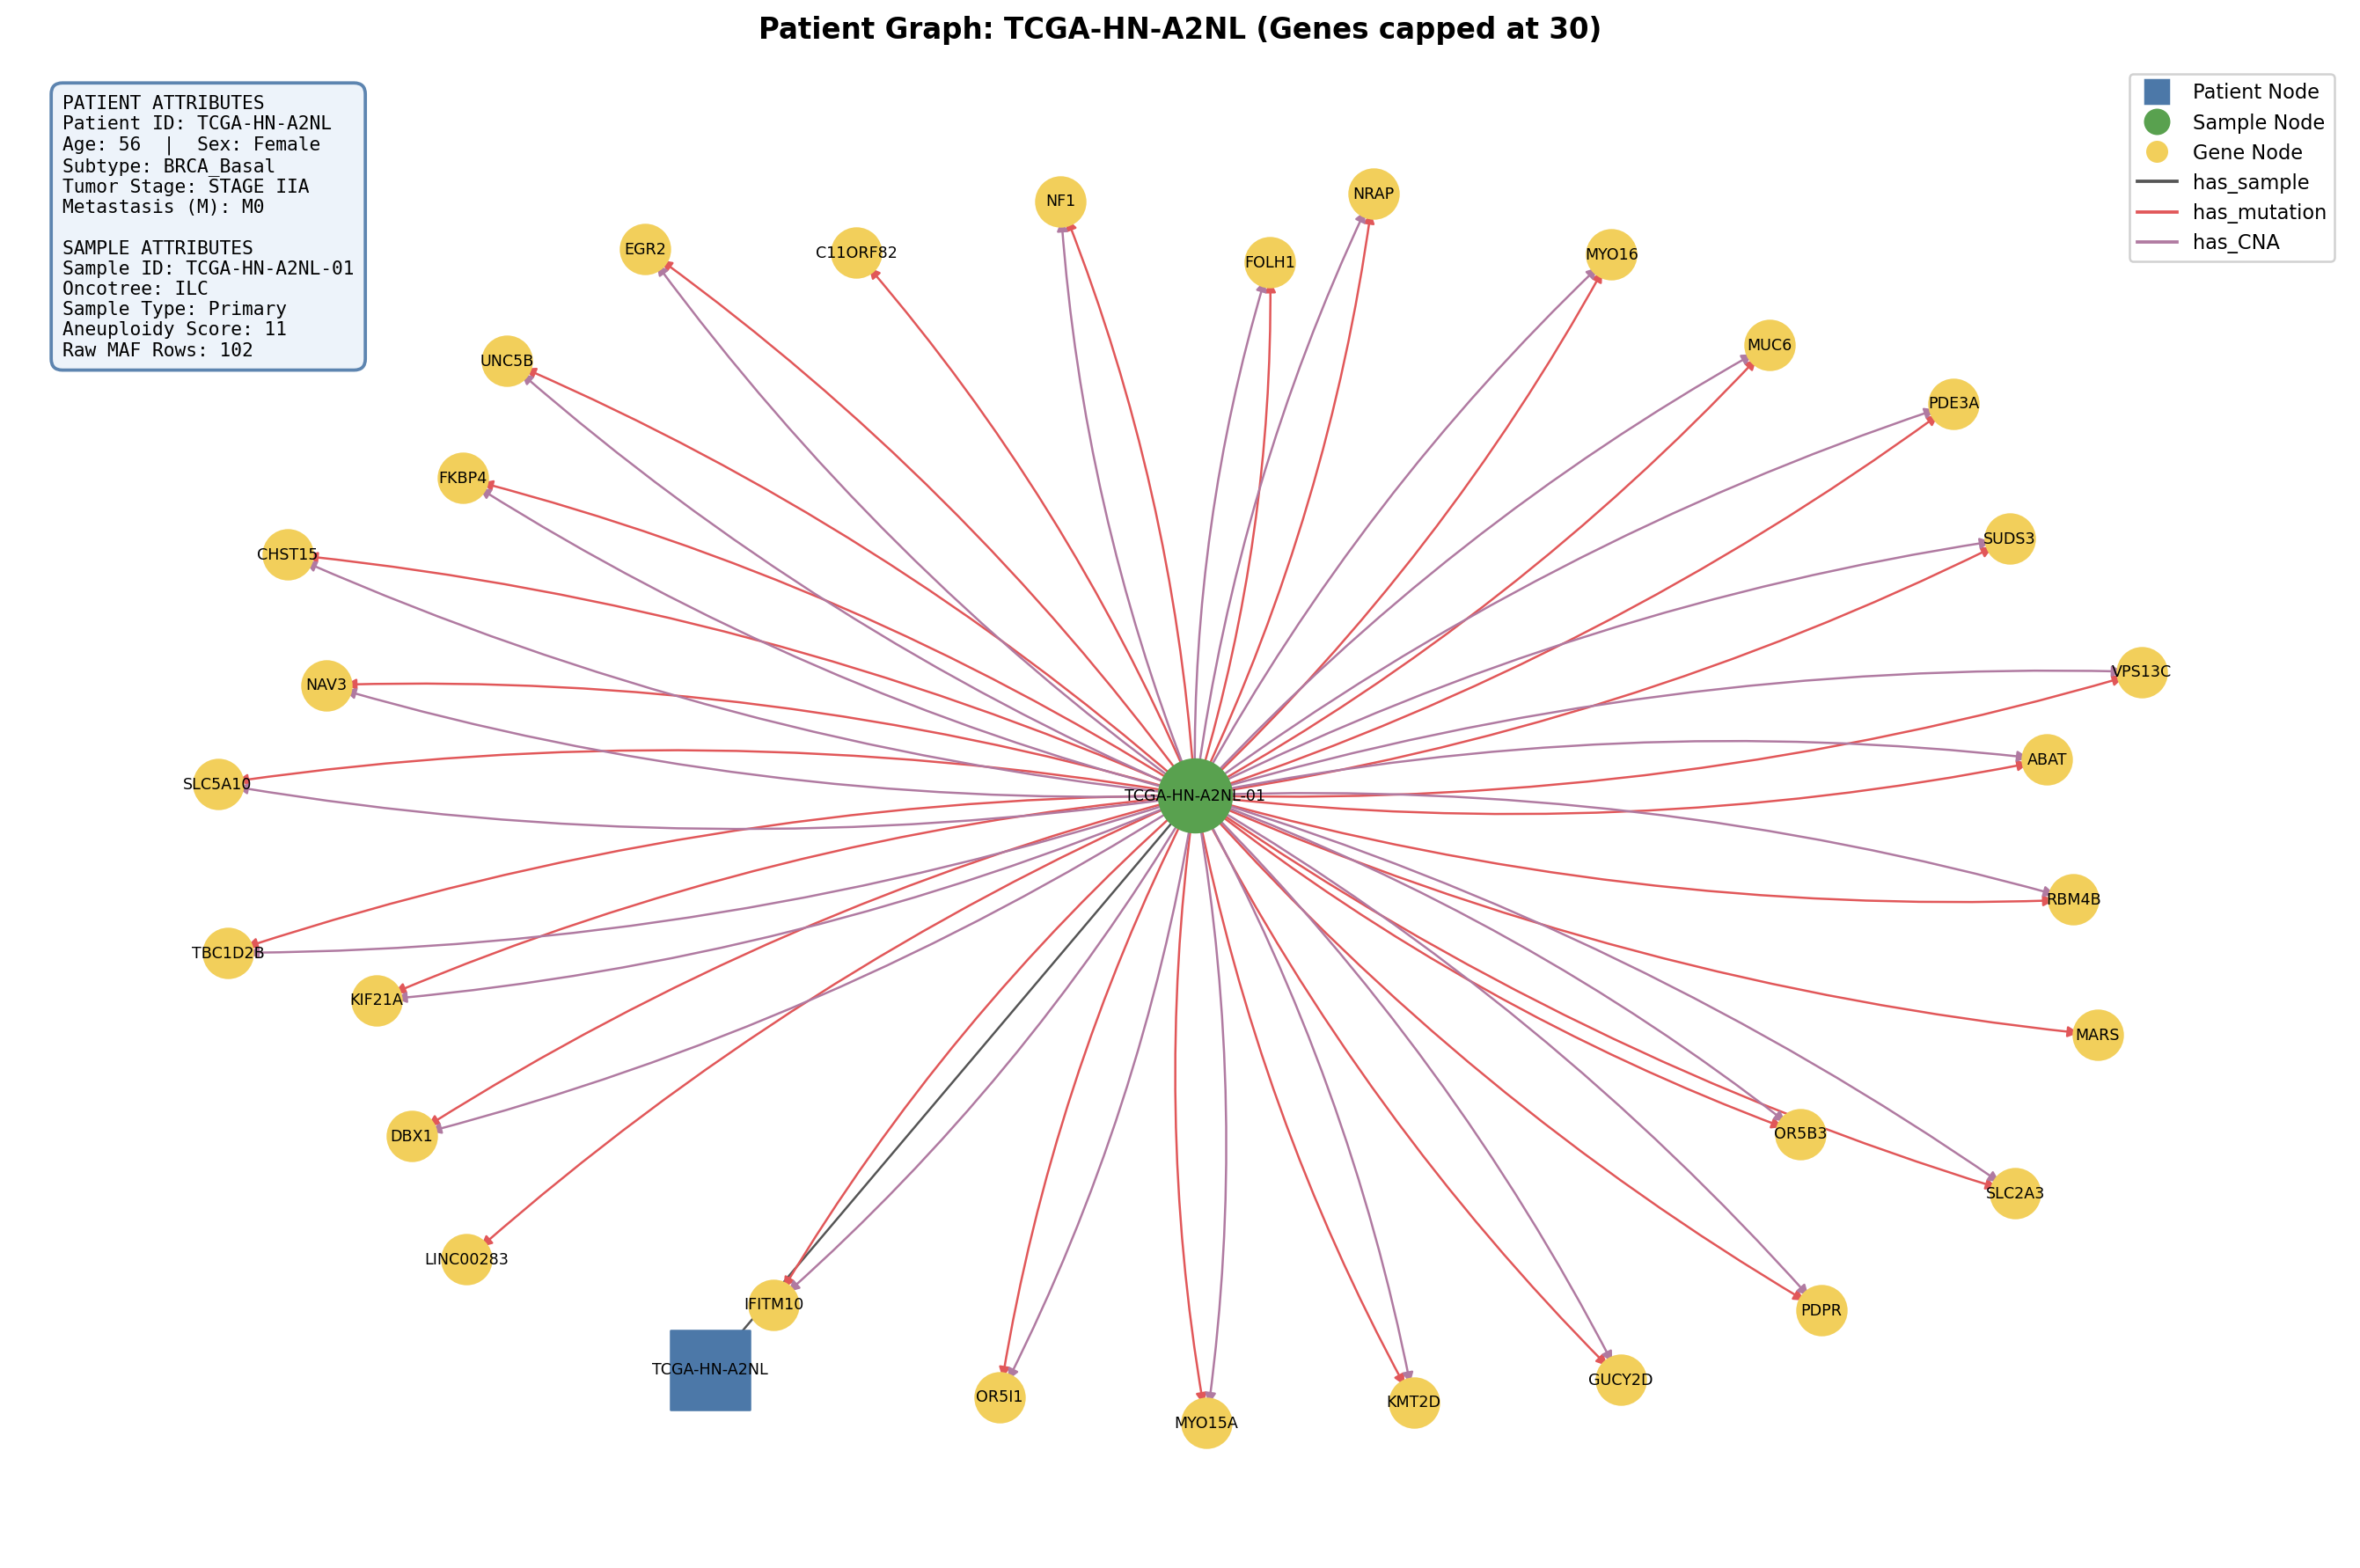

=== TCGA-B6-A0I6: Unclassified Subtype, Stage IIA - Edge Case (0 Mutations, 0 CNA) ===


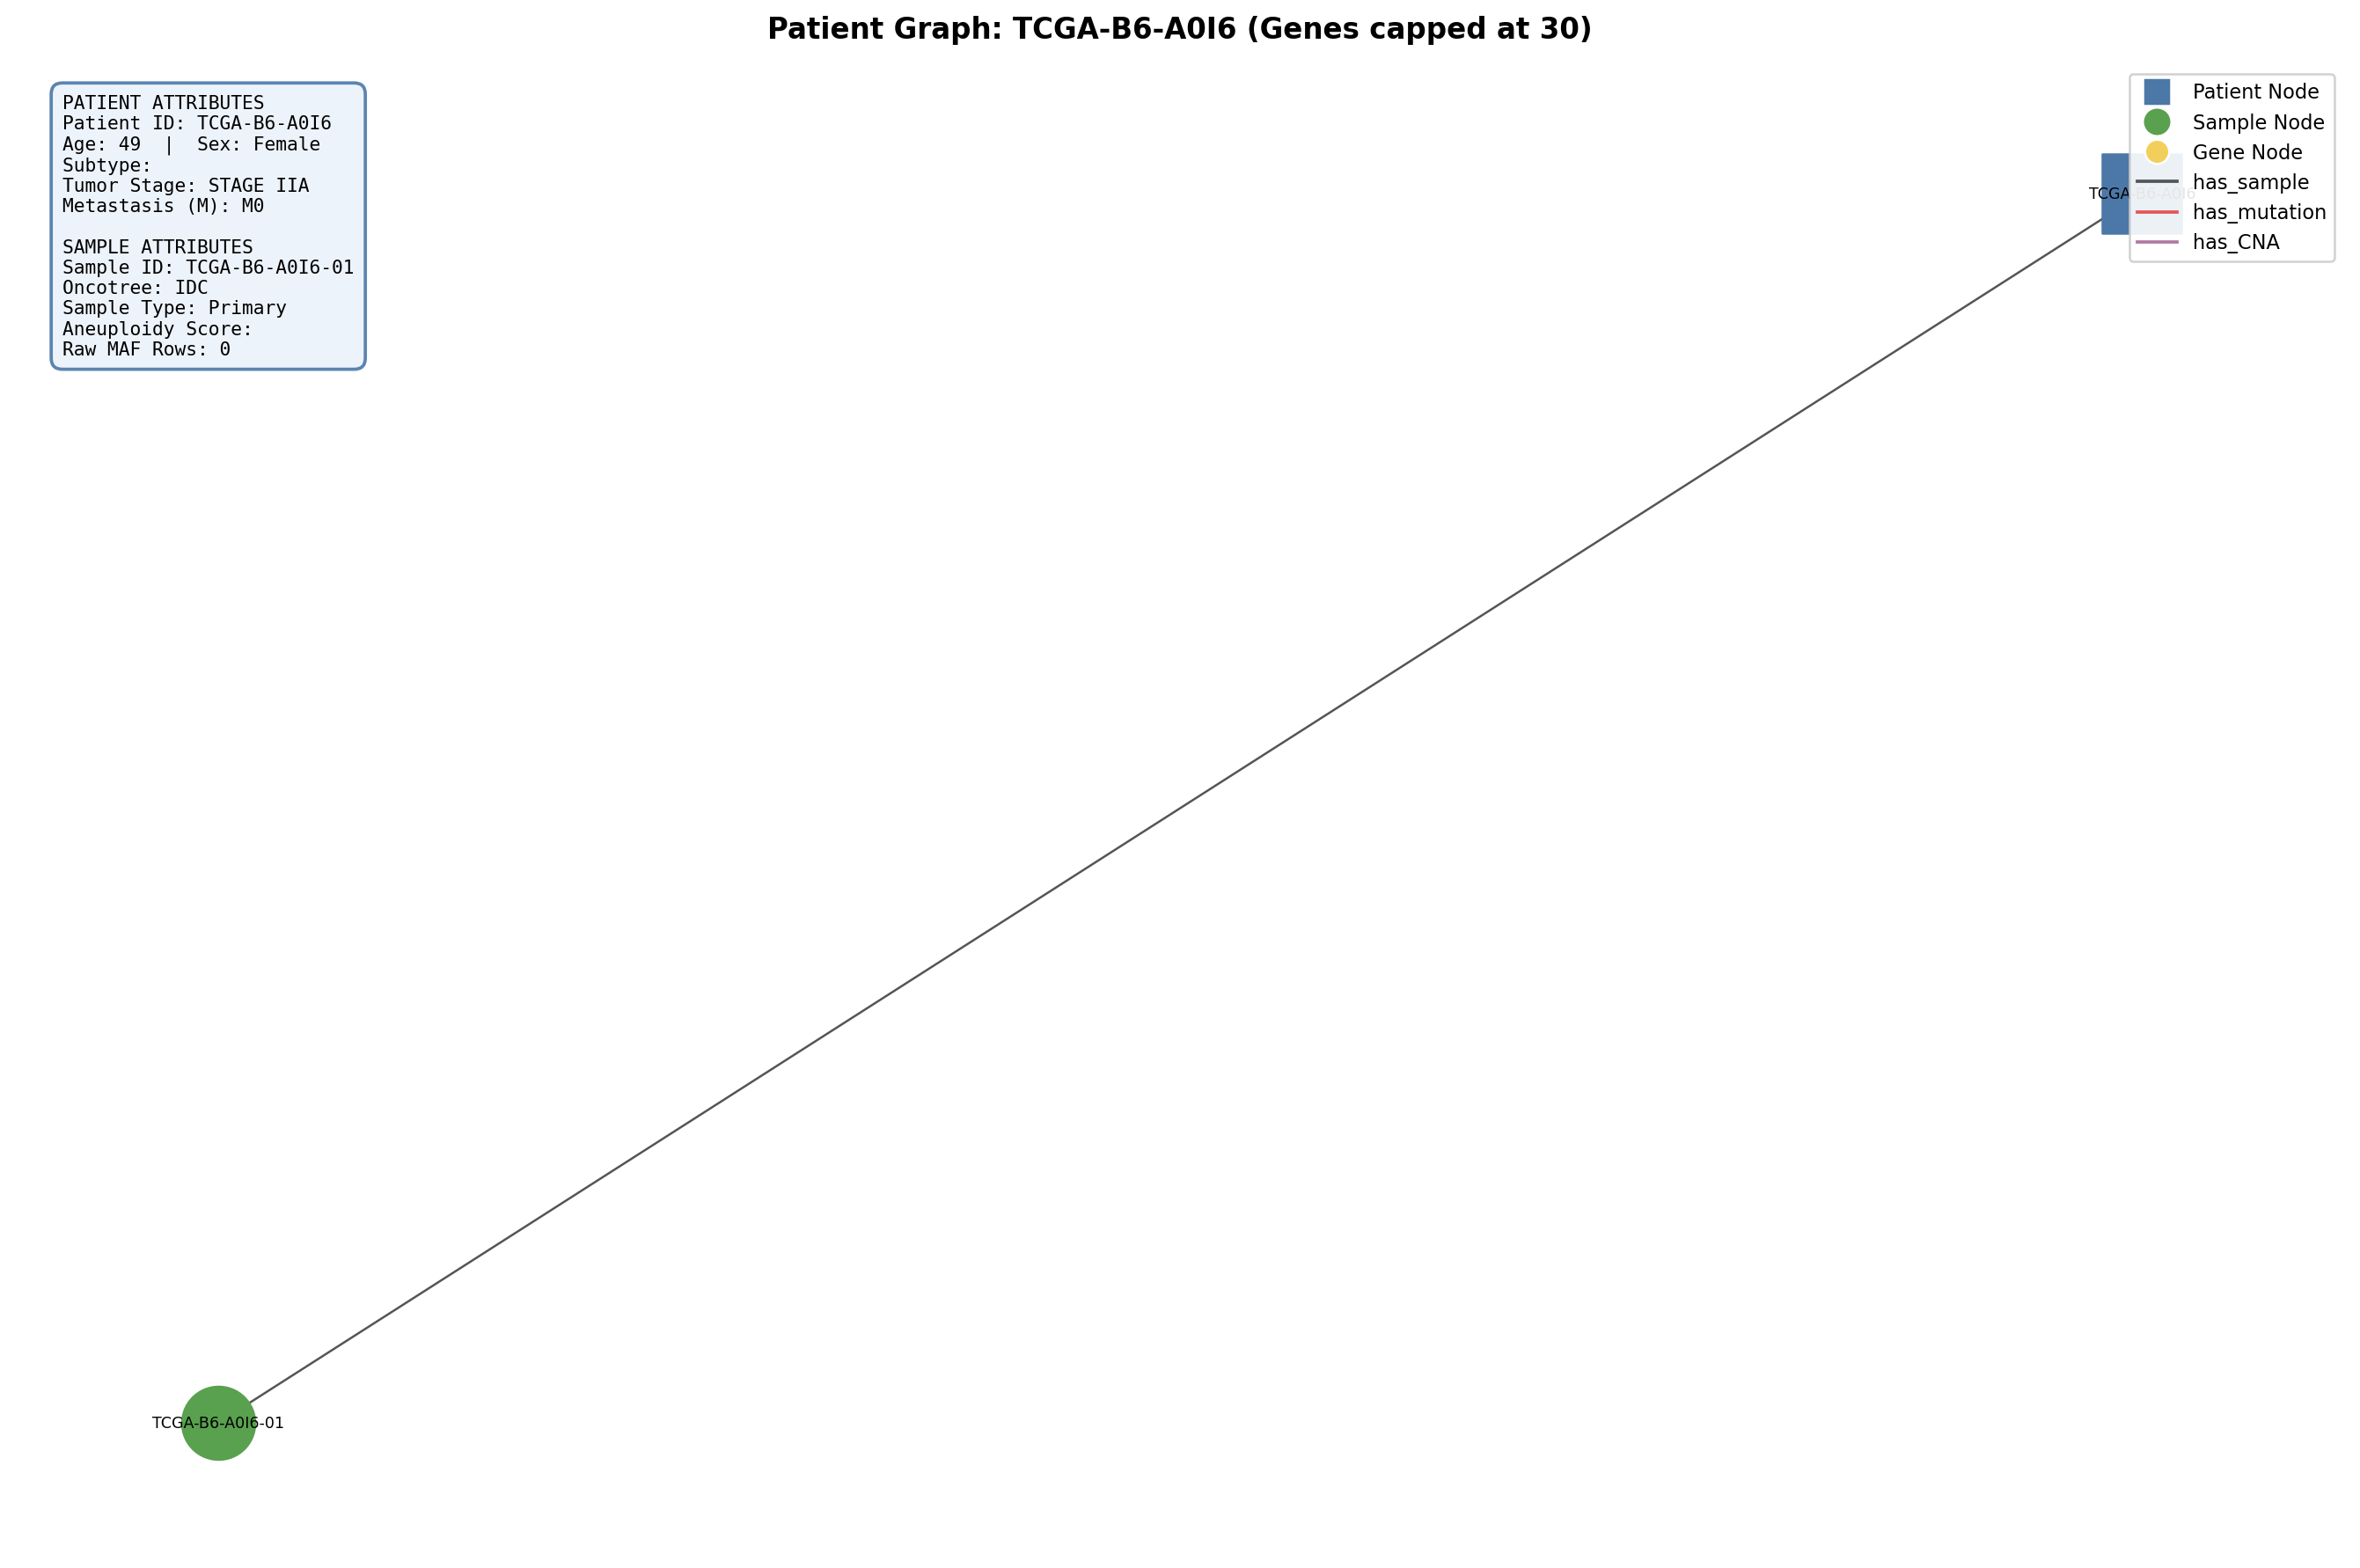

In [15]:
from IPython.display import Image, display

# Display representative patients
sample_visualizations = [
    ('TCGA-AR-A0TS', 'Basal Subtype, Stage IIB - High CNA & Mutations'),
    ('TCGA-BH-A0GZ', 'Luminal A Subtype, Stage IIA - Moderate Mutations'),
    ('TCGA-HN-A2NL', 'Basal Subtype, Stage IIA - Extreme CNA Burden (24k+ genes)'),
    ('TCGA-B6-A0I6', 'Unclassified Subtype, Stage IIA - Edge Case (0 Mutations, 0 CNA)')
]

for patient_id, desc in sample_visualizations:
    img_path = OUTPUT_DIR / 'visualizations' / f'{patient_id}.png'
    if img_path.exists():
        print(f'=== {patient_id}: {desc} ===')
        display(Image(filename=str(img_path)))
    else:
        print(f'Image not found: {img_path}')